# T36 -- Phase 3: composite multi-feature source score on real data

**`source_score` is an evidence-ranking score for comparing candidates within one
run/configuration. It is NOT a probability, confidence, likelihood, or certainty of
source identity. The top-ranked candidate below is NOT proven to be the actual
physical source of the spill** -- exactly like every other Phase 2/3 screening
quantity in this project.

In [1]:
import os, sys, time
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from iste.ensemble_run import EnsembleRunRecords
from iste.analysis_grid import generate_analysis_grid
from iste.candidate_extraction import CandidateExtractionConfig, find_candidate_peaks
from iste.kdtree_neighborhood import build_particle_neighborhood_index
from iste.particle_query import query_particle_slice
from iste.support_features import SupportFeatureConfig, compute_support_map
from iste.phase3_composite import (
    DEFAULT_WEIGHTS, PERSISTENCE_EMPHASIS_WEIGHTS, DISPERSION_EMPHASIS_WEIGHTS,
    compute_source_scores_for_candidates, EVIDENCE_RANKING_DISCLAIMER,
)

## 1. Load real Stage III result + regenerate candidates with support grids

In [2]:
history_path = os.path.join(REPO_ROOT, "results", "actual_data", "stage3_particle_history.npz")
cached = np.load(history_path, allow_pickle=True)

def _none_if_empty(arr):
    return None if arr.size == 0 else arr

records = EnsembleRunRecords(
    particle_id=cached["particle_id"], forcing_member_id=cached["forcing_member_id"],
    observation_pixel_id=cached["observation_pixel_id"], timestamp=cached["timestamp"],
    lat=cached["lat"], lon=cached["lon"], log_weight=cached["log_weight"], valid=cached["valid"],
    death_time=_none_if_empty(cached["death_time"]), death_lat=_none_if_empty(cached["death_lat"]),
    death_lon=_none_if_empty(cached["death_lon"]), death_reason=_none_if_empty(cached["death_reason"]),
    survival_mark=_none_if_empty(cached["survival_mark"]),
)
t_obs = np.datetime64(np.max(records.timestamp), "ns")
grid = generate_analysis_grid(t_obs, window_hours=72.0, interval_hours=1.0)
historical_timestamps = grid[1:]
print(f"loaded {records.n_records} real rows; {len(historical_timestamps)} historical timestamps")

loaded 240024 real rows; 72 historical timestamps


In [3]:
spill_data = json.load(open(os.path.join(REPO_ROOT, "data", "database_payload.json"), encoding="utf-8"))
spill = next(s for s in spill_data["spills"] if s["image_filename"] == "ow-0008.jpg")
obs_bbox = spill["bounding_box"]
valid_mask = records.valid
lat_min = min(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].min()))
lat_max = max(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].max()))
lon_min = min(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].min()))
lon_max = max(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].max()))
PAD_DEG = 0.03
support_lat_grid = np.arange(lat_min - PAD_DEG, lat_max + PAD_DEG, 0.003)
support_lon_grid = np.arange(lon_min - PAD_DEG, lon_max + PAD_DEG, 0.003)
NEIGHBORHOOD_RADIUS_M = 1000.0
support_config = SupportFeatureConfig()
extraction_config = CandidateExtractionConfig(peak_neighborhood_cells=5, min_separation_m=1500.0, core_radius_m=1000.0)
lon_mesh, lat_mesh = np.meshgrid(support_lon_grid, support_lat_grid)

t0 = time.time()
all_candidates = []
support_grids_by_t_s = {}
for t_s in historical_timestamps:
    slice_ = query_particle_slice(records, t_s)
    index = build_particle_neighborhood_index(slice_)
    support_map = compute_support_map(
        index, lat_mesh.ravel(), lon_mesh.ravel(), radius_m=NEIGHBORHOOD_RADIUS_M, config=support_config,
    )
    grid_vals = np.array([sf.support for sf in support_map]).reshape(len(support_lat_grid), len(support_lon_grid))
    support_grids_by_t_s[np.datetime64(t_s, "ns")] = grid_vals
    all_candidates.extend(find_candidate_peaks(support_map, support_lat_grid, support_lon_grid, t_s, config=extraction_config))
t1 = time.time()
print(f"regenerated {len(all_candidates)} real candidates + {len(support_grids_by_t_s)} support grids in {t1-t0:.1f}s")

regenerated 280 real candidates + 72 support grids in 59.5s


## 2. Compute T36 composite source scores (DEFAULT configuration)

In [4]:
t2 = time.time()
default_scores = compute_source_scores_for_candidates(
    records, all_candidates, support_grids_by_t_s, neighborhood_radius_m=NEIGHBORHOOD_RADIUS_M,
    weights=DEFAULT_WEIGHTS,
)
t3 = time.time()
print(f"computed T36 source scores for {len(default_scores)} real candidates in {t3-t2:.1f}s")
print()
print(EVIDENCE_RANKING_DISCLAIMER)

computed T36 source scores for 280 real candidates in 41.6s

source_score is an evidence-ranking score for comparing candidates within one run/configuration. It is NOT a probability, confidence, likelihood, or certainty of source identity, and a high score is not proof of actual physical source identity.


## 3. Configured weights vs. effective weights (AIS unavailable for every real candidate)

In [5]:
sample = default_scores[0]
print("configured weights:", sample.configured_weights)
print("effective weights (AIS unavailable):", {k: round(v, 4) for k, v in sample.effective_weights.items()})
print(f"sum of effective weights: {sum(sample.effective_weights.values()):.6f}")
n_ais_available = sum(1 for s in default_scores if s.ais_evidence is not None)
print(f"candidates with AIS available: {n_ais_available} / {len(default_scores)}")
all_same_effective = all(s.effective_weights == sample.effective_weights for s in default_scores)
print(f"all 280 real candidates share the identical effective-weight vector: {all_same_effective}")

configured weights: {'support': 0.35, 'persistence': 0.2, 'convergence': 0.1, 'dispersion': 0.15, 'ais': 0.2, 'initial_bias': 0.0, 'persistence_count': 0.0}
effective weights (AIS unavailable): {'support': 0.4375, 'persistence': 0.25, 'convergence': 0.125, 'dispersion': 0.1875, 'ais': 0.0, 'initial_bias': 0.0, 'persistence_count': 0.0}
sum of effective weights: 1.000000
candidates with AIS available: 0 / 280
all 280 real candidates share the identical effective-weight vector: True


## 4. Score distribution

In [6]:
scores = np.array([s.source_score for s in default_scores])
print(f"n candidates: {len(scores)}")
print(f"NaN scores: {int(np.isnan(scores).sum())}")
df_scores = pd.Series(scores)
print(df_scores.describe(percentiles=[.1, .25, .5, .75, .9, .95]).round(4).to_string())

n candidates: 280
NaN scores: 0
count    280.0000
mean       0.5636
std        0.3953
min        0.2006
10%        0.2693
25%        0.2909
50%        0.2935
75%        1.0331
90%        1.1936
95%        1.3148
max        1.4620


## 5. Top-10 comparison against the T17 raw-Support baseline

In [7]:
raw_support = {c.candidate_id: c.support_score for c in all_candidates}
composite = {s.candidate_id: s.source_score for s in default_scores}

top10_raw = sorted(raw_support, key=lambda cid: -raw_support[cid])[:10]
top10_composite = sorted(composite, key=lambda cid: -composite[cid])[:10]

print("top-10 by raw T17 support_score:")
for cid in top10_raw:
    print(f"  {cid:30s} raw_support={raw_support[cid]:.2f}")
print()
print("top-10 by T36 source_score (DEFAULT):")
for cid in top10_composite:
    print(f"  {cid:30s} source_score={composite[cid]:.4f}  raw_support={raw_support[cid]:.2f}")

overlap = set(top10_raw) & set(top10_composite)
print()
print(f"top-10 overlap: {len(overlap)}/10")
print(f"entering top-10 (in composite, not raw): {sorted(set(top10_composite) - set(top10_raw))}")
print(f"leaving top-10 (in raw, not composite):   {sorted(set(top10_raw) - set(top10_composite))}")

top-10 by raw T17 support_score:
  2019-10-14T22:00:00_cand000    raw_support=4675.43
  2019-10-14T21:00:00_cand000    raw_support=4573.32
  2019-10-14T20:00:00_cand000    raw_support=4411.98
  2019-10-14T19:00:00_cand000    raw_support=4288.16
  2019-10-14T18:00:00_cand000    raw_support=4153.03
  2019-10-14T17:00:00_cand000    raw_support=3961.17
  2019-10-14T16:00:00_cand000    raw_support=3807.23
  2019-10-14T15:00:00_cand000    raw_support=3656.80
  2019-10-14T14:00:00_cand000    raw_support=3529.66
  2019-10-14T13:00:00_cand000    raw_support=3463.28

top-10 by T36 source_score (DEFAULT):
  2019-10-11T23:00:00_cand000    source_score=1.4620  raw_support=855.31
  2019-10-12T04:00:00_cand000    source_score=1.4388  raw_support=929.98
  2019-10-12T00:00:00_cand000    source_score=1.4355  raw_support=861.42
  2019-10-12T05:00:00_cand000    source_score=1.4354  raw_support=942.20
  2019-10-12T01:00:00_cand000    source_score=1.4275  raw_support=875.98
  2019-10-12T06:00:00_cand000    

In [8]:
all_ids = list(raw_support.keys())
raw_vals = [raw_support[cid] for cid in all_ids]
composite_vals = [composite[cid] for cid in all_ids]
rank_corr = spearmanr(raw_vals, composite_vals)
print(f"Spearman rank correlation (source_score vs. raw support_score, all 280 candidates): {rank_corr.correlation:.4f}")

raw_ranks = pd.Series(raw_vals).rank(ascending=False)
composite_ranks = pd.Series(composite_vals).rank(ascending=False)
rank_changes = (raw_ranks - composite_ranks).abs()
print(f"mean |rank change|: {rank_changes.mean():.2f}  max |rank change|: {rank_changes.max():.0f}")

Spearman rank correlation (source_score vs. raw support_score, all 280 candidates): 0.7156
mean |rank change|: 46.29  max |rank change|: 153


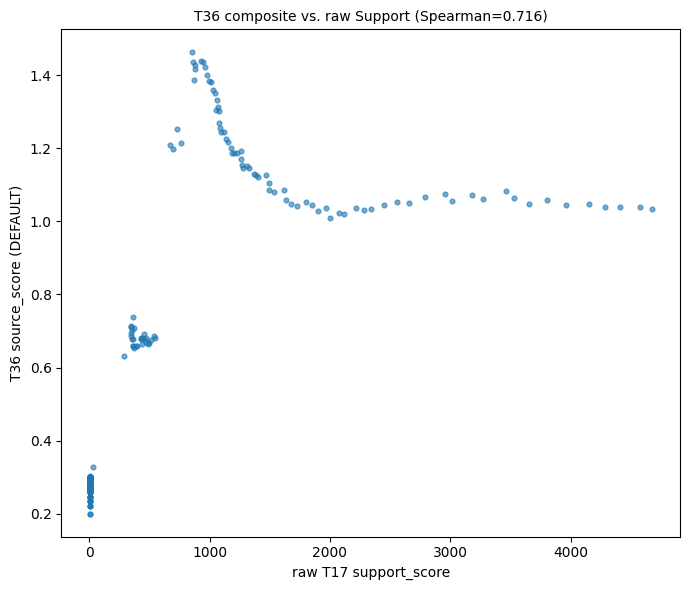

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(raw_vals, composite_vals, s=12, alpha=0.6)
ax.set_xlabel("raw T17 support_score"); ax.set_ylabel("T36 source_score (DEFAULT)")
ax.set_title(f"T36 composite vs. raw Support (Spearman={rank_corr.correlation:.3f})", fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T36_composite_vs_raw_support.png"), dpi=100)
plt.show()

## 6. Sensitivity analysis: DEFAULT vs. PERSISTENCE-EMPHASIS vs. DISPERSION-EMPHASIS

In [10]:
t4 = time.time()
persistence_scores = compute_source_scores_for_candidates(
    records, all_candidates, support_grids_by_t_s, neighborhood_radius_m=NEIGHBORHOOD_RADIUS_M,
    weights=PERSISTENCE_EMPHASIS_WEIGHTS,
)
dispersion_scores = compute_source_scores_for_candidates(
    records, all_candidates, support_grids_by_t_s, neighborhood_radius_m=NEIGHBORHOOD_RADIUS_M,
    weights=DISPERSION_EMPHASIS_WEIGHTS,
)
t5 = time.time()
print(f"computed 2 additional sensitivity configurations in {t5-t4:.1f}s")

computed 2 additional sensitivity configurations in 83.7s


In [11]:
persistence_map = {s.candidate_id: s.source_score for s in persistence_scores}
dispersion_map = {s.candidate_id: s.source_score for s in dispersion_scores}

top10_persistence = sorted(persistence_map, key=lambda cid: -persistence_map[cid])[:10]
top10_dispersion = sorted(dispersion_map, key=lambda cid: -dispersion_map[cid])[:10]

print("top-10 by PERSISTENCE-EMPHASIS:")
for cid in top10_persistence:
    print(f"  {cid:30s} score={persistence_map[cid]:.4f}")
print()
print("top-10 by DISPERSION-EMPHASIS:")
for cid in top10_dispersion:
    print(f"  {cid:30s} score={dispersion_map[cid]:.4f}")

print()
print(f"PERSISTENCE-EMPHASIS overlap with DEFAULT top-10: {len(set(top10_persistence) & set(top10_composite))}/10")
print(f"DISPERSION-EMPHASIS overlap with DEFAULT top-10:  {len(set(top10_dispersion) & set(top10_composite))}/10")

top-10 by PERSISTENCE-EMPHASIS:
  2019-10-11T23:00:00_cand000    score=1.2828
  2019-10-12T04:00:00_cand000    score=1.2696
  2019-10-12T05:00:00_cand000    score=1.2667
  2019-10-12T00:00:00_cand000    score=1.2647
  2019-10-12T01:00:00_cand000    score=1.2614
  2019-10-12T06:00:00_cand000    score=1.2587
  2019-10-12T02:00:00_cand000    score=1.2539
  2019-10-12T07:00:00_cand000    score=1.2439
  2019-10-12T09:00:00_cand000    score=1.2342
  2019-10-12T08:00:00_cand000    score=1.2331

top-10 by DISPERSION-EMPHASIS:
  2019-10-11T23:00:00_cand000    score=1.7688
  2019-10-12T00:00:00_cand000    score=1.7245
  2019-10-12T01:00:00_cand000    score=1.6909
  2019-10-12T04:00:00_cand000    score=1.6792
  2019-10-12T02:00:00_cand000    score=1.6697
  2019-10-12T05:00:00_cand000    score=1.6626
  2019-10-12T06:00:00_cand000    score=1.6421
  2019-10-12T03:00:00_cand000    score=1.6224
  2019-10-12T07:00:00_cand000    score=1.5903
  2019-10-12T08:00:00_cand000    score=1.5683

PERSISTENCE-EMP

In [12]:
corr_default_persistence = spearmanr([composite[c] for c in all_ids], [persistence_map[c] for c in all_ids])
corr_default_dispersion = spearmanr([composite[c] for c in all_ids], [dispersion_map[c] for c in all_ids])
corr_persistence_dispersion = spearmanr([persistence_map[c] for c in all_ids], [dispersion_map[c] for c in all_ids])
print(f"Spearman(DEFAULT, PERSISTENCE-EMPHASIS)  = {corr_default_persistence.correlation:.4f}")
print(f"Spearman(DEFAULT, DISPERSION-EMPHASIS)    = {corr_default_dispersion.correlation:.4f}")
print(f"Spearman(PERSISTENCE-EMPHASIS, DISPERSION-EMPHASIS) = {corr_persistence_dispersion.correlation:.4f}")

Spearman(DEFAULT, PERSISTENCE-EMPHASIS)  = 0.9992
Spearman(DEFAULT, DISPERSION-EMPHASIS)    = 0.9982
Spearman(PERSISTENCE-EMPHASIS, DISPERSION-EMPHASIS) = 0.9962


## 7. Pairwise correlation diagnostics among the active evidence components (this run)

In [13]:
diag_rows = [dict(
    candidate_id=s.candidate_id, support=s.support_evidence, persistence=s.persistence_evidence,
    convergence=s.convergence_evidence, dispersion=s.dispersion_evidence,
    initial_bias=s.initial_bias_evidence, source_score=s.source_score,
) for s in default_scores]
diag_df = pd.DataFrame(diag_rows)
corr_cols = ["support", "persistence", "convergence", "dispersion", "initial_bias", "source_score"]
print("Pearson:")
print(diag_df[corr_cols].corr(method="pearson").round(3).to_string())
print()
print("Spearman:")
print(diag_df[corr_cols].corr(method="spearman").round(3).to_string())

Pearson:
              support  persistence  convergence  dispersion  initial_bias  source_score
support         1.000        0.305        0.934       0.927         0.979         0.994
persistence     0.305        1.000        0.353       0.278         0.291         0.337
convergence     0.934        0.353        1.000       0.775         0.973         0.910
dispersion      0.927        0.278        0.775       1.000         0.852         0.960
initial_bias    0.979        0.291        0.973       0.852         1.000         0.959
source_score    0.994        0.337        0.910       0.960         0.959         1.000

Spearman:
              support  persistence  convergence  dispersion  initial_bias  source_score
support         1.000        0.268        0.767       0.976         0.773         0.823
persistence     0.268        1.000        0.538       0.305         0.367         0.693
convergence     0.767        0.538        1.000       0.764         0.791         0.890
dispersion  

## Known limitations / caveats (restated, per instruction)

- **The top-ranked candidate is NOT proven to be the actual physical source.**
  `source_score` is an evidence-ranking score, not a probability.
- Weights are heuristic/configurable, not scientifically validated.
- `w_initial` (T30) is `0.0` by default -- reported as a diagnostic field only, since
  Mahalanobis consistency has no scientifically justified directional interpretation as
  source evidence.
- `dispersion_evidence` (T33) carries a known, unmodified age-correlation history (strong
  at the top-candidate level, weak at the population level) -- included with no age
  correction of any kind.
- AIS is unavailable for all 280 real candidates in this project; its configured weight
  is always excluded (not zeroed) from the active set.
- No Stage III module, and no existing T14-T35 module, was modified.

## 8. Requested review diagnostic: the dominant T31 track, member by member

**No production code changed for the diagnostic itself** except one already-flagged,
already-approved-for-fixing gap (the `NaN`-vs-`None` handling fixed inside
`phase3_composite.py` at implementation time, not here). Sections F/G below use
`CompositeWeights` with different values purely as diagnostic inputs to the existing,
unmodified `compute_source_score` -- the production `DEFAULT_WEIGHTS` constant itself
is never changed.

Purpose: determine whether T33's rise with backward age reflects meaningful increasing
relative concentration of the dominant candidate against its own timestamp-specific
population, or is effectively acting as a systematic older-timestamp reward. Does NOT
conclude that older or newer timestamps are more likely correct, and does NOT claim
source identity.

In [14]:
from iste.phase3_persistence import track_candidate_persistence
from iste.phase3_composite import CompositeWeights

tracks = track_candidate_persistence(all_candidates)
dominant_track = max(tracks, key=lambda tr: tr.persistence_count)
print(f"dominant track: {dominant_track.track_id}, persistence_count={dominant_track.persistence_count}, "
      f"duration={dominant_track.persistence_duration_hours}h, continuity={dominant_track.temporal_continuity():.4f}")

track_candidate_ids = set(dominant_track.candidate_ids)
track_candidates = [c for c in all_candidates if c.candidate_id in track_candidate_ids]
track_candidates.sort(key=lambda c: np.datetime64(c.t_s, "ns"))
print(f"track has {len(track_candidates)} members")

dominant track: track0000, persistence_count=72, duration=71.0h, continuity=1.0000
track has 72 members


In [15]:
from iste.phase3_screening import compute_screening_scores_for_candidates
from iste.phase3_convergence import compute_convergence_scores_for_candidates
from iste.phase3_dispersion import compute_dispersion_aware_scores_for_candidates
from iste.phase3_initial_bias import compute_timestamp_cloud_stats, compute_initial_bias_influence
from iste.phase3_ais import compute_ais_evidence
from iste.phase3_composite import compute_source_score

screening_results = compute_screening_scores_for_candidates(track_candidates, support_grids_by_t_s)
convergence_results = compute_convergence_scores_for_candidates(records, track_candidates, persistence_tracks=tracks)
dispersion_results = compute_dispersion_aware_scores_for_candidates(records, track_candidates, neighborhood_radius_m=NEIGHBORHOOD_RADIUS_M)
ais_results_track = [compute_ais_evidence(c) for c in track_candidates]

cloud_stats_by_t_s = {}
initial_bias_results = []
for c in track_candidates:
    t_s = np.datetime64(c.t_s, "ns")
    if t_s not in cloud_stats_by_t_s:
        cloud_stats_by_t_s[t_s] = compute_timestamp_cloud_stats(records, t_s)
    initial_bias_results.append(compute_initial_bias_influence(cloud_stats_by_t_s[t_s], c.y_peak, c.x_peak))

default_track_results = [
    compute_source_score(
        c, screening_score=screening_results[i], persistence_track=dominant_track,
        convergence_score=convergence_results[i], dispersion_score=dispersion_results[i],
        initial_bias=initial_bias_results[i], ais_evidence=ais_results_track[i], weights=DEFAULT_WEIGHTS,
    )
    for i, c in enumerate(track_candidates)
]
print(f"computed per-member evidence + default composite for {len(track_candidates)} track members")

computed per-member evidence + default composite for 72 track members


In [16]:
def population_median_local_density(t_s, radius_m):
    slice_ = query_particle_slice(records, t_s)
    index = build_particle_neighborhood_index(slice_)
    positions = np.column_stack([index.x_m, index.y_m])
    counts = index._tree.query_ball_point(positions, radius_m, return_length=True)
    return float(np.median(counts))

pop_median_density = {}
for c in track_candidates:
    t_s = np.datetime64(c.t_s, "ns")
    if t_s not in pop_median_density:
        pop_median_density[t_s] = population_median_local_density(t_s, NEIGHBORHOOD_RADIUS_M)
print(f"computed population median local density for {len(pop_median_density)} timestamps")

computed population median local density for 72 timestamps


In [17]:
rows = []
for i, c in enumerate(track_candidates):
    t_s = np.datetime64(c.t_s, "ns")
    age_hours = float((t_obs - t_s) / np.timedelta64(1, "h"))
    r = default_track_results[i]
    cs = cloud_stats_by_t_s[t_s]
    lam1, lam2 = np.sort(np.linalg.eigvalsh(cs.covariance_m2))[::-1]
    det = float(lam1 * lam2)
    dr = dispersion_results[i]
    rows.append(dict(
        candidate_id=c.candidate_id, age_hours=age_hours, raw_support=c.support_score,
        support_evidence=r.support_evidence, convergence_evidence=r.convergence_evidence,
        dispersion_evidence=r.dispersion_evidence, persistence_evidence=r.persistence_evidence,
        composite_score=r.source_score,
        w_eff_support=r.effective_weights["support"], w_eff_persistence=r.effective_weights["persistence"],
        w_eff_convergence=r.effective_weights["convergence"], w_eff_dispersion=r.effective_weights["dispersion"],
        contrib_support=r.effective_weights["support"] * r.support_evidence,
        contrib_persistence=r.effective_weights["persistence"] * r.persistence_evidence,
        contrib_convergence=r.effective_weights["convergence"] * r.convergence_evidence,
        contrib_dispersion=r.effective_weights["dispersion"] * r.dispersion_evidence,
        covariance_det=det, candidate_local_density=dr.particle_count_actual,
        population_median_local_density=pop_median_density[t_s],
        t33_expected_density=dr.expected_density, t33_dispersion_ratio=dr.dispersion_aware_score,
    ))

track_df = pd.DataFrame(rows)
track_df["composite_rank"] = track_df["composite_score"].rank(ascending=False).astype(int)
print(track_df[["age_hours","raw_support","support_evidence","convergence_evidence",
                 "dispersion_evidence","persistence_evidence","composite_score","composite_rank"]]
      .iloc[::6].round(4).to_string(index=False))

 age_hours  raw_support  support_evidence  convergence_evidence  dispersion_evidence  persistence_evidence  composite_score  composite_rank
      72.0     855.3053            1.4662                0.5859               2.6524                   1.0           1.4620               1
      66.0     942.2044            1.5438                0.5614               2.3459                   1.0           1.4354               4
      60.0    1045.1676            1.5249                0.6044               1.9106                   1.0           1.3509              13
      54.0    1089.0405            1.4831                0.6071               1.4953                   1.0           1.2551              19
      48.0    1189.3797            1.4283                0.6134               1.2581                   1.0           1.1875              27
      42.0    1275.9256            1.3915                0.6214               1.1135                   1.0           1.1453              32
      36.0    1466.9

### A-B. Spearman correlation with age: raw evidence vs. weighted contribution

In [18]:
print("A. raw evidence:")
for col in ["support_evidence", "convergence_evidence", "dispersion_evidence", "persistence_evidence"]:
    if track_df[col].std() == 0:
        print(f"  {col:22s} constant (std=0) -- correlation undefined")
    else:
        print(f"  {col:22s} Spearman={spearmanr(track_df['age_hours'], track_df[col]).correlation:+.4f}")
print()
print("B. weighted contribution:")
for col in ["contrib_support", "contrib_persistence", "contrib_convergence", "contrib_dispersion"]:
    if track_df[col].std() == 0:
        print(f"  {col:22s} constant (std=0) -- correlation undefined")
    else:
        print(f"  {col:22s} Spearman={spearmanr(track_df['age_hours'], track_df[col]).correlation:+.4f}")

A. raw evidence:
  support_evidence       Spearman=+0.9088
  convergence_evidence   Spearman=-0.9925
  dispersion_evidence    Spearman=+0.8621
  persistence_evidence   constant (std=0) -- correlation undefined

B. weighted contribution:
  contrib_support        Spearman=+0.9088
  contrib_persistence    constant (std=0) -- correlation undefined
  contrib_convergence    Spearman=-0.9925
  contrib_dispersion     Spearman=+0.8621


### C-E. Oldest-vs-newest decomposition

In [19]:
oldest = track_df.loc[track_df["age_hours"].idxmax()]
newest = track_df.loc[track_df["age_hours"].idxmin()]
diff = oldest["composite_score"] - newest["composite_score"]
print(f"C. composite_score(oldest, {oldest['age_hours']:.0f}h) - composite_score(newest, {newest['age_hours']:.0f}h) = {diff:+.4f}")

t33_diff = oldest["contrib_dispersion"] - newest["contrib_dispersion"]
t32_diff = oldest["contrib_convergence"] - newest["contrib_convergence"]
support_diff = oldest["contrib_support"] - newest["contrib_support"]
persistence_diff = oldest["contrib_persistence"] - newest["contrib_persistence"]
print(f"D. T33 (dispersion) contribution to diff: {t33_diff:+.4f} ({100*t33_diff/diff:.1f}%)")
print(f"E. T32 (convergence) contribution to diff: {t32_diff:+.4f} ({100*t32_diff/diff:.1f}%)")
print(f"   T29/T34 (support) contribution to diff: {support_diff:+.4f} ({100*support_diff/diff:.1f}%)")
print(f"   T31 (persistence) contribution to diff: {persistence_diff:+.4f} ({100*persistence_diff/diff:.1f}%)")
print(f"   sum = {support_diff+persistence_diff+t32_diff+t33_diff:+.4f} (should equal {diff:+.4f})")

C. composite_score(oldest, 72h) - composite_score(newest, 1h) = +0.4290
D. T33 (dispersion) contribution to diff: +0.3174 (74.0%)
E. T32 (convergence) contribution to diff: -0.0253 (-5.9%)
   T29/T34 (support) contribution to diff: +0.1369 (31.9%)
   T31 (persistence) contribution to diff: +0.0000 (0.0%)
   sum = +0.4290 (should equal +0.4290)


### F. Within-track ordering with T33 removed (diagnostic weights only, production unchanged)

In [20]:
t33_removed_weights = CompositeWeights(
    w_support=DEFAULT_WEIGHTS.w_support, w_persistence=DEFAULT_WEIGHTS.w_persistence,
    w_convergence=DEFAULT_WEIGHTS.w_convergence, w_dispersion=0.0, w_ais=DEFAULT_WEIGHTS.w_ais,
)
no_t33_results = [
    compute_source_score(
        c, screening_score=screening_results[i], persistence_track=dominant_track,
        convergence_score=convergence_results[i], dispersion_score=dispersion_results[i],
        initial_bias=initial_bias_results[i], ais_evidence=ais_results_track[i], weights=t33_removed_weights,
    )
    for i, c in enumerate(track_candidates)
]
track_df["composite_score_no_t33"] = [r.source_score for r in no_t33_results]
track_df["composite_rank_no_t33"] = track_df["composite_score_no_t33"].rank(ascending=False).astype(int)
print(f"effective weights with T33 removed: {no_t33_results[0].effective_weights}")
print(f"Spearman(age, score) WITHOUT T33 = {spearmanr(track_df['age_hours'], track_df['composite_score_no_t33']).correlation:+.4f}")
print(f"Spearman(age, score) WITH T33    = {spearmanr(track_df['age_hours'], track_df['composite_score']).correlation:+.4f}")
print(f"oldest rank: without T33={int(track_df.loc[track_df['age_hours'].idxmax(),'composite_rank_no_t33'])}/72  "
      f"with T33={int(track_df.loc[track_df['age_hours'].idxmax(),'composite_rank'])}/72")
print(f"newest rank: without T33={int(track_df.loc[track_df['age_hours'].idxmin(),'composite_rank_no_t33'])}/72  "
      f"with T33={int(track_df.loc[track_df['age_hours'].idxmin(),'composite_rank'])}/72")

effective weights with T33 removed: {'support': 0.5384615384615384, 'persistence': 0.3076923076923077, 'convergence': 0.15384615384615385, 'dispersion': 0.0, 'ais': 0.0, 'initial_bias': 0.0, 'persistence_count': 0.0}
Spearman(age, score) WITHOUT T33 = +0.8712
Spearman(age, score) WITH T33    = +0.9032
oldest rank: without T33=21/72  with T33=1/72
newest rank: without T33=71/72  with T33=67/72


### G. Diagnostic T33-weight sweep (production `DEFAULT_WEIGHTS` never modified)

In [21]:
base_others = DEFAULT_WEIGHTS.w_support + DEFAULT_WEIGHTS.w_persistence + DEFAULT_WEIGHTS.w_convergence + DEFAULT_WEIGHTS.w_ais
for d in [0.0, 0.05, 0.10, 0.15, 0.20]:
    scale = (1.0 - d) / base_others
    sweep_weights = CompositeWeights(
        w_support=DEFAULT_WEIGHTS.w_support * scale, w_persistence=DEFAULT_WEIGHTS.w_persistence * scale,
        w_convergence=DEFAULT_WEIGHTS.w_convergence * scale, w_dispersion=d,
        w_ais=DEFAULT_WEIGHTS.w_ais * scale,
    )
    sweep_scores = [
        compute_source_score(
            c, screening_score=screening_results[i], persistence_track=dominant_track,
            convergence_score=convergence_results[i], dispersion_score=dispersion_results[i],
            initial_bias=initial_bias_results[i], ais_evidence=ais_results_track[i], weights=sweep_weights,
        ).source_score
        for i, c in enumerate(track_candidates)
    ]
    corr = spearmanr(track_df["age_hours"], sweep_scores).correlation
    ranks = pd.Series(sweep_scores).rank(ascending=False)
    print(f"  w_dispersion={d:.2f}: Spearman(age,score)={corr:+.4f}  "
          f"oldest_rank={int(ranks[track_df['age_hours'].idxmax()])}/72  newest_rank={int(ranks[track_df['age_hours'].idxmin()])}/72")

  w_dispersion=0.00: Spearman(age,score)=+0.8712  oldest_rank=21/72  newest_rank=71/72
  w_dispersion=0.05: Spearman(age,score)=+0.9077  oldest_rank=4/72  newest_rank=71/72
  w_dispersion=0.10: Spearman(age,score)=+0.9088  oldest_rank=1/72  newest_rank=68/72
  w_dispersion=0.15: Spearman(age,score)=+0.9032  oldest_rank=1/72  newest_rank=67/72
  w_dispersion=0.20: Spearman(age,score)=+0.8950  oldest_rank=1/72  newest_rank=64/72


### Physical diagnostics: does the candidate get more concentrated, or does the whole ensemble get more diffuse?

In [22]:
phys_cols = ["age_hours", "covariance_det", "candidate_local_density", "population_median_local_density",
             "t33_expected_density", "t33_dispersion_ratio"]
print(track_df[phys_cols].iloc[::6].round(3).to_string(index=False))
print()
# a simple, fully model-free empirical concentration ratio, for comparison against T33's Gaussian-based ratio
track_df["empirical_ratio"] = track_df["candidate_local_density"] / track_df["population_median_local_density"]
print(track_df[["age_hours", "empirical_ratio", "t33_dispersion_ratio"]].iloc[::6].round(3).to_string(index=False))
print()
print(f"Spearman(age, empirical_ratio) = {spearmanr(track_df['age_hours'], track_df['empirical_ratio']).correlation:+.4f}")
print(f"Spearman(age, t33_dispersion_ratio) = {spearmanr(track_df['age_hours'], track_df['t33_dispersion_ratio']).correlation:+.4f}")

 age_hours  covariance_det  candidate_local_density  population_median_local_density  t33_expected_density  t33_dispersion_ratio
      72.0    5.140478e+13                    340.0                            153.0               128.186                 2.652
      66.0    3.862909e+13                    376.0                            162.0               160.276                 2.346
      60.0    2.952202e+13                    404.0                            166.5               211.448                 1.911
      54.0    2.338887e+13                    402.0                            173.0               268.840                 1.495
      48.0    1.475864e+13                    444.0                            206.5               352.919                 1.258
      42.0    1.161698e+13                    475.0                            229.5               426.566                 1.114
      36.0    8.204785e+12                    547.0                            266.0             

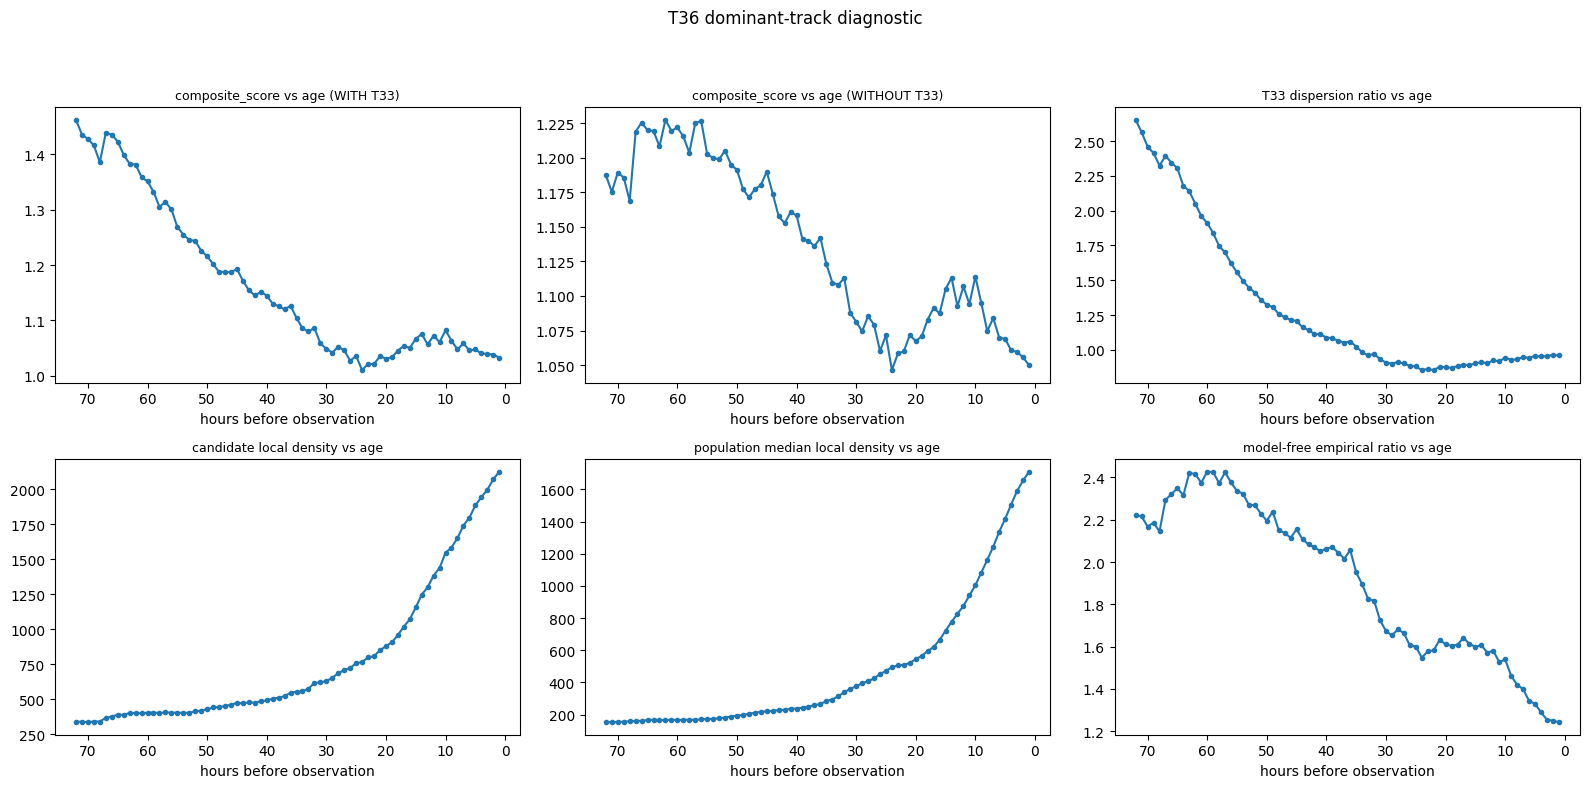

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col, title in [
    (axes[0,0], "composite_score", "composite_score vs age (WITH T33)"),
    (axes[0,1], "composite_score_no_t33", "composite_score vs age (WITHOUT T33)"),
    (axes[0,2], "t33_dispersion_ratio", "T33 dispersion ratio vs age"),
    (axes[1,0], "candidate_local_density", "candidate local density vs age"),
    (axes[1,1], "population_median_local_density", "population median local density vs age"),
    (axes[1,2], "empirical_ratio", "model-free empirical ratio vs age"),
]:
    ax.plot(track_df["age_hours"], track_df[col], "-o", markersize=3)
    ax.set_xlabel("hours before observation"); ax.set_title(title, fontsize=9)
    ax.invert_xaxis()
fig.suptitle("T36 dominant-track diagnostic", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T36_dominant_track_diagnostic.png"), dpi=100)
plt.show()

## Diagnostic conclusion (2026-09-24) -- no production code or weights changed

This section does not conclude that older or newer timestamps are more likely to be the
true source, and does not claim source identity. It only characterizes the mechanism
behind the top-10 inversion reported in Section 5-6 above.